In [1]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import re

C1true = 1.0
C2true = 0.01

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [2]:
from pathlib import Path

PATH = Path(r"C:\\Users\\user\\OneDrive\\Desktop\\PINN_codes")

In [3]:
data=loadmat(PATH / "cylinder_nektar_wake.mat")
print(data)

{'__header__': b'MATLAB 5.0 MAT-file Platform: posix, Created on: Fri Sep 22 23:02:15 2017', '__version__': '1.0', '__globals__': [], 'X_star': array([[ 1.        , -2.        ],
       [ 1.07070707, -2.        ],
       [ 1.14141414, -2.        ],
       ...,
       [ 7.85858586,  2.        ],
       [ 7.92929293,  2.        ],
       [ 8.        ,  2.        ]]), 't': array([[ 0. ],
       [ 0.1],
       [ 0.2],
       [ 0.3],
       [ 0.4],
       [ 0.5],
       [ 0.6],
       [ 0.7],
       [ 0.8],
       [ 0.9],
       [ 1. ],
       [ 1.1],
       [ 1.2],
       [ 1.3],
       [ 1.4],
       [ 1.5],
       [ 1.6],
       [ 1.7],
       [ 1.8],
       [ 1.9],
       [ 2. ],
       [ 2.1],
       [ 2.2],
       [ 2.3],
       [ 2.4],
       [ 2.5],
       [ 2.6],
       [ 2.7],
       [ 2.8],
       [ 2.9],
       [ 3. ],
       [ 3.1],
       [ 3.2],
       [ 3.3],
       [ 3.4],
       [ 3.5],
       [ 3.6],
       [ 3.7],
       [ 3.8],
       [ 3.9],
       [ 4. ],
       [ 4.1

In [4]:
U_star = data["U_star"] # N Z X T
P_star = data["p_star"]
t_star = data["t"]
X_star = data["X_star"]

print("U_star.shape", U_star.shape)
print("U_star", U_star)

U_star.shape (5000, 2, 200)
U_star [[[ 1.11419216e+00  1.11755721e+00  1.11956933e+00 ...  1.16105653e+00
    1.16209316e+00  1.16287446e+00]
  [-4.09649775e-03  1.09212754e-03  3.28231641e-03 ... -1.14679740e-02
   -1.46226631e-02 -1.78649950e-02]]

 [[ 1.11102707e+00  1.11424311e+00  1.11623549e+00 ...  1.16119046e+00
    1.16250501e+00  1.16355997e+00]
  [ 3.93130751e-04  6.09231658e-03  8.54240777e-03 ... -3.69331211e-03
   -6.90960992e-03 -1.02375054e-02]]

 [[ 1.10748452e+00  1.11049848e+00  1.11244362e+00 ...  1.16080365e+00
    1.16241577e+00  1.16375737e+00]
  [ 4.42777717e-03  1.06585027e-02  1.33831464e-02 ...  4.14245483e-03
    8.86993440e-04 -2.50609725e-03]]

 ...

 [[ 1.04183122e+00  1.07052197e+00  1.08570786e+00 ...  1.03561691e+00
    1.01482352e+00  9.95607444e-01]
  [-1.53233747e-01 -1.52906494e-01 -1.50934775e-01 ...  1.70410243e-01
    1.74234015e-01  1.74978509e-01]]

 [[ 1.03144583e+00  1.05940483e+00  1.07424671e+00 ...  1.05086925e+00
    1.02921296e+00  1.00

In [5]:
print("p_star.shape", P_star.shape)
print("p_star", P_star)

p_star.shape (5000, 200)
p_star [[-0.10815457 -0.11115509 -0.1123679  ... -0.10035143 -0.09845376
  -0.09658143]
 [-0.10560371 -0.10881921 -0.1101648  ... -0.10137256 -0.09959008
  -0.09781616]
 [-0.10257633 -0.10599348 -0.10746686 ... -0.10204929 -0.10039933
  -0.09874095]
 ...
 [ 0.0066028   0.00272234  0.00081532 ...  0.01152894  0.01414437
   0.01651662]
 [ 0.007892    0.00402109  0.00209731 ...  0.00927242  0.01200894
   0.01451151]
 [ 0.00915729  0.00530504  0.00337089 ...  0.00691424  0.00975565
   0.01238328]]


In [6]:
# load the training data
from pathlib import Path


def load_training_data(num):
    PATH = Path(r"C:\\Users\\user\\OneDrive\\Desktop\\PINN_codes")
    data = loadmat(PATH / "cylinder_nektar_wake.mat")

    #print(data)

    U_star = data["U_star"] # N X 2 X T
    P_star = data["p_star"] # N X T
    t_star = data["t"]      # T
    X_star = data["X_star"] # N X 2  - geometry

    #print("U_star.shape", U_star.shape)
    #print("U_star", U_star)

    N = X_star.shape[0]
    T = t_star.shape[0]

    XX = np.tile(X_star[:,0:1], (1,T))
    YY = np.tile(X_star[:,1:2], (1,T))
    TT = np.tile(t_star, (1,N)).T
    UU = U_star[:,0,:]
    VV = U_star[:,1,:]
    PP = P_star

    x = XX.flatten()[:, None] # NT x 1
    y = YY.flatten()[:, None]
    t = TT.flatten()[:, None]
    u = UU.flatten()[:, None]
    v = VV.flatten()[:, None]
    p = PP.flatten()[:, None]

    data1 = np.concatenate([x,y,t,u,v,p], 1)

    # X = [1,8], Y = [-2,2], time = [0,7] - filtering the data
    data2 = data1[:,:][data1[:,2] <= +7]
    data3 = data2[:,:][data2[:,0] >= +1] # on X direction
    data4 = data3[:,:][data3[:,0] <= +8] # on X direction
    data5 = data4[:,:][data4[:,1] >= -2]
    data6 = data5[:,:][data5[:,1] <= +2]

    data_domain = data6

    idx = np.random.choice(data_domain.shape[0], num, replace=False)

    x_train = data_domain[idx, 0:1]
    y_train = data_domain[idx, 1:2]
    t_train = data_domain[idx, 2:3]
    u_train = data_domain[idx, 3:4]
    v_train = data_domain[idx, 4:5]
    p_train = data_domain[idx, 5:6]

    return [x_train, y_train, t_train, u_train, v_train, p_train]

In [7]:
[ob_x, ob_y, ob_t, ob_u, ob_v, ob_p] = load_training_data(num = 7000)

print("ob_y.shape", ob_y.shape)
print("ob_y", ob_y)

ob_xyt = np.hstack((ob_x, ob_y, ob_t)) # input of neural network. the output will be u,v,p

print("ob_xyt.shape", ob_xyt.shape)
print("ob_xyt", ob_xyt)

ob_y.shape (7000, 1)
ob_y [[ 0.6122449 ]
 [-0.36734694]
 [-0.53061224]
 ...
 [-1.18367347]
 [-1.42857143]
 [ 0.28571429]]
ob_xyt.shape (7000, 3)
ob_xyt [[ 3.26262626  0.6122449   3.2       ]
 [ 5.1010101  -0.36734694  2.5       ]
 [ 5.87878788 -0.53061224  6.7       ]
 ...
 [ 7.08080808 -1.18367347  6.3       ]
 [ 2.41414141 -1.42857143  6.2       ]
 [ 6.23232323  0.28571429  6.4       ]]


In [8]:
C1 = dde.Variable(0.0)
C2 = dde.Variable(0.0)

In [9]:
def Navier_stokes_Eq(x,y):
    u = y[:,0:1]
    v = y[:,1:2]
    p = y[:,2:3]

    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1) # with respect to y
    du_t = dde.grad.jacobian(y, x, i=0, j=2)

    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    dv_t = dde.grad.jacobian(y, x, i=1, j=2)

    dp_x = dde.grad.jacobian(y, x, i=2, j=0)
    dp_y = dde.grad.jacobian(y, x, i=2, j=1)
    dp_t = dde.grad.jacobian(y, x, i=2, j=2)

    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)

    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)

    continuity = du_x + dv_y
    x_momentum = du_t + C1*(u*du_x + v*du_y) + dp_x - C2 * (du_xx + du_yy) 
    y_momentum = dv_t + C1*(u*dv_x + v*dv_y) + dp_y - C2 * (dv_xx + dv_yy)

    return [continuity, x_momentum, y_momentum]

In [10]:
# define the depp neural network (DNN)
layer_size = [3] + [50] * 6 + [3]
activation = "tanh"
initializer = "Glorot uniform"
net = dde.nn.FNN(layer_size, activation, initializer)

In [11]:
# computation domain
Lx_min, Lx_max = 1.0, 8.0
Ly_min, Ly_max = -2.0, +2.0

space_domain = dde.geometry.Rectangle([Lx_min,Ly_min],[Lx_max,Ly_max])

time_domain = dde.geometry.TimeDomain(0,7)

geometrytime = dde.geometry.GeometryXTime(space_domain, time_domain)

In [12]:
# B.C
observe_u = dde.icbc.PointSetBC(ob_xyt, ob_u, component=0)
observe_v = dde.icbc.PointSetBC(ob_xyt, ob_v, component=1)
observe_p = dde.icbc.PointSetBC(ob_xyt, ob_p, component=2)

In [13]:
# training dataset used to calculate the loss
data = dde.data.TimePDE(geometrytime, Navier_stokes_Eq, 
                        [observe_u, observe_v, observe_p],
                        num_domain= 700,
                        num_boundary=200,
                        num_initial=100,
                        anchors=ob_xyt)

we can have another experiment using the same code but removing the osberve_p from the above cell in data because of having particle image velocimetry to see the result of this code.

Compiling model...
'compile' took 2.603864 s

Training model...

Step      Train loss                                                      Test loss                                                       Test metric
0         [1.81e-03, 4.76e-04, 3.17e-03, 1.17e+00, 7.59e-02, 9.05e-02]    [1.81e-03, 4.76e-04, 3.17e-03, 1.17e+00, 7.59e-02, 9.05e-02]    []  
1000      [5.82e-04, 8.85e-04, 1.06e-03, 2.50e-03, 4.99e-03, 6.49e-04]    [5.82e-04, 8.85e-04, 1.06e-03, 2.50e-03, 4.99e-03, 6.49e-04]    []  

Best model at step 1000:
  train loss: 1.07e-02
  test loss: 1.07e-02
  test metric: []

'train' took 66.697934 s



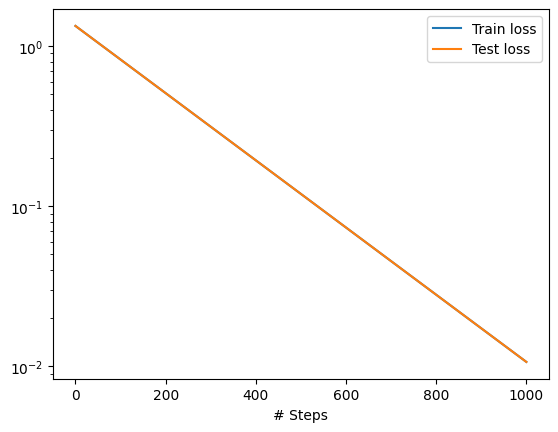

Compiling model...
'compile' took 0.000686 s

Training model...

Step      Train loss                                                      Test loss                                                       Test metric
1000      [5.82e-04, 8.85e-04, 1.06e-03, 2.50e-03, 4.99e-03, 6.49e-04]    [5.82e-04, 8.85e-04, 1.06e-03, 2.50e-03, 4.99e-03, 6.49e-04]    []  
2000      [3.33e-04, 4.95e-04, 5.38e-04, 1.31e-03, 1.76e-03, 2.73e-04]    [3.33e-04, 4.95e-04, 5.38e-04, 1.31e-03, 1.76e-03, 2.73e-04]    []  

Best model at step 2000:
  train loss: 4.70e-03
  test loss: 4.70e-03
  test metric: []

'train' took 64.792444 s



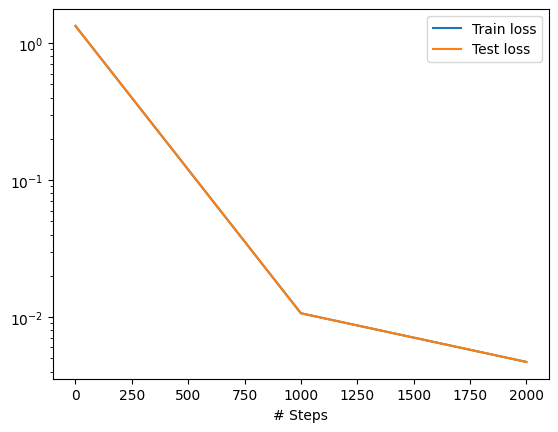

Mean Residual 0.01514023


In [14]:
model = dde.Model(data, net)

results_file_C1_C2 = 'C:\\Users\\user\\OneDrive\\Desktop\\PINN_codes\\variables_main_C1_C2.dat'
variable = dde.callbacks.VariableValue([C1,C2], period=100, filename=results_file_C1_C2)

model.compile('adam', lr=1e-3, external_trainable_variables=[C1,C2])
loss_history, train_state = model.train(iterations=1000, 
                                        callbacks=[variable], 
                                        display_every=1000, 
                                        disregard_previous_best=True) 

dde.saveplot(loss_history, train_state, issave=False, isplot=True)


model.compile('adam', lr=1e-4, external_trainable_variables=[C1,C2])
loss_history, train_state = model.train(iterations=1000, 
                                        callbacks=[variable], 
                                        display_every=1000, 
                                        disregard_previous_best=True) 

dde.saveplot(loss_history, train_state, issave=False, isplot=True)

f = model.predict(ob_xyt, operator=Navier_stokes_Eq)
print("Mean Residual", np.mean(np.absolute(f)))

you can go up to 10_000 iterations. its just an example of running IPINNs on NS eq using DeepXDE lib.

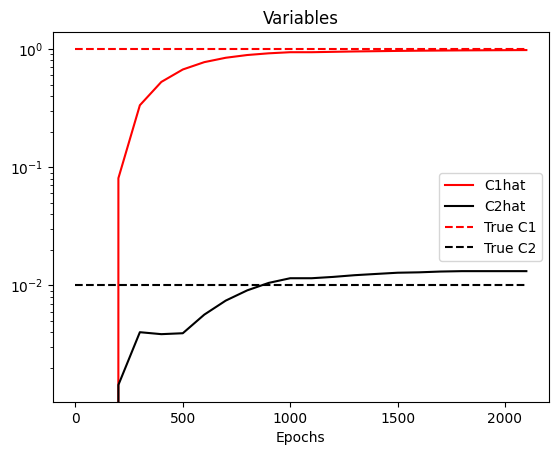

In [15]:
# Plot Variables:
# reopen saved data using callbacks in results_file_C1_C2

results_file_C1_C2 = 'C:\\Users\\user\\OneDrive\\Desktop\\PINN_codes\\variables_main_C1_C2.dat'

lines = open(results_file_C1_C2, "r").readlines()
# read output data in fnamevar
Chat = np.array(
    [
        np.fromstring(
            min(re.findall(re.escape("[") + "(.*?)" + re.escape("]"), line), key=len),
            sep=",",
        )
        for line in lines
    ]
)
l, c = Chat.shape
plt.semilogy(range(0, l * 100, 100), Chat[:, 0], "r-")
plt.semilogy(range(0, l * 100, 100), Chat[:, 1], "k-")
plt.semilogy(range(0, l * 100, 100), np.ones(Chat[:, 0].shape) * C1true, "r--")
plt.semilogy(range(0, l * 100, 100), np.ones(Chat[:, 1].shape) * C2true, "k--")
plt.legend(["C1hat", "C2hat", "True C1", "True C2"], loc="right")
plt.xlabel("Epochs")
plt.title("Variables")
plt.show()

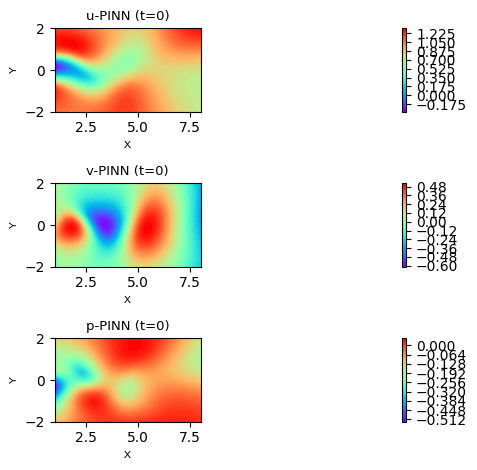

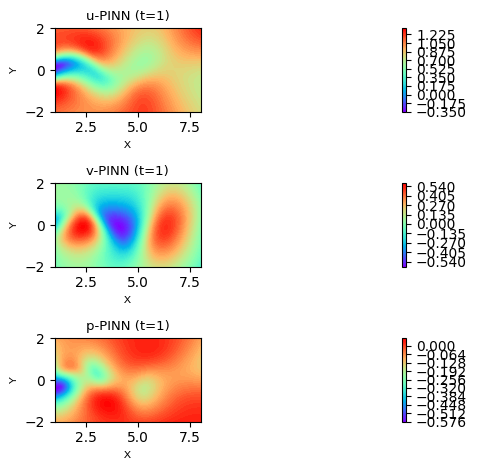

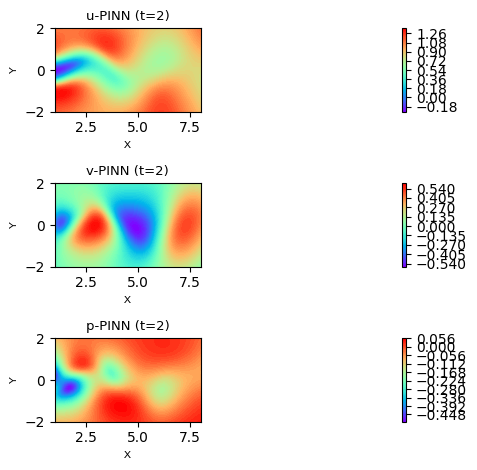

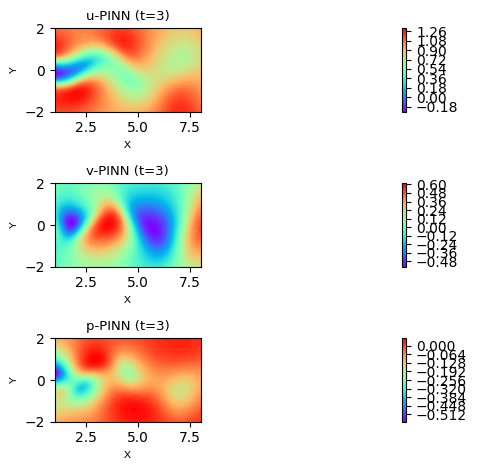

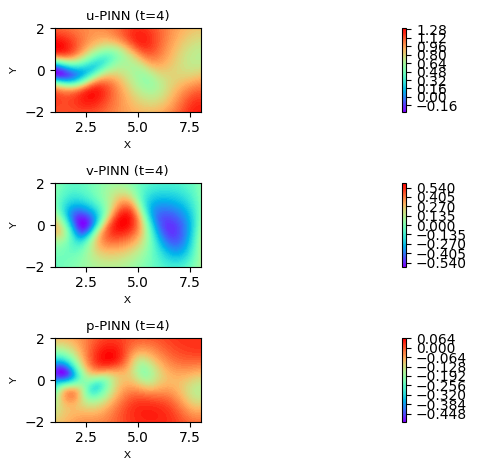

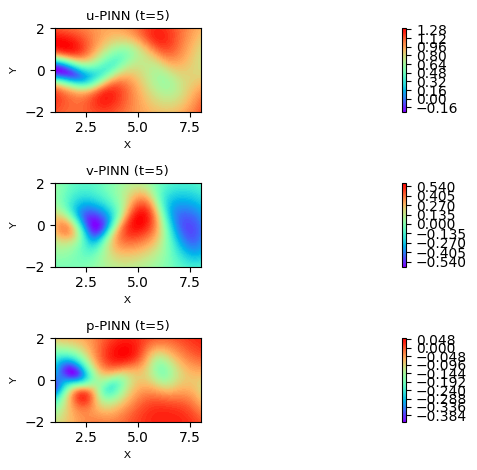

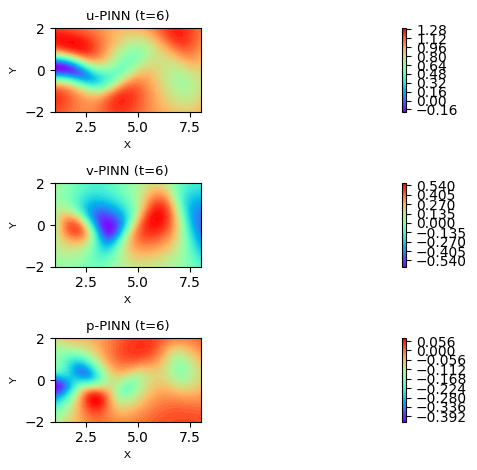

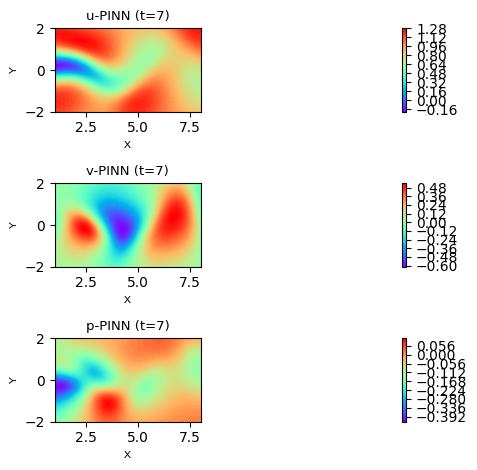

In [16]:
# Plot the velocity and pressure distribution of the flow field:
for t in range(0, 8):
    [ob_x, ob_y, ob_t, ob_u, ob_v, ob_p] = load_training_data(num=140000)
    xyt_pred = np.hstack((ob_x, ob_y, t * np.ones((len(ob_x), 1))))
    uvp_pred = model.predict(xyt_pred)
    x_pred, y_pred, t_pred = xyt_pred[:, 0], xyt_pred[:, 1], xyt_pred[:, 2]
    u_pred, v_pred, p_pred = uvp_pred[:, 0], uvp_pred[:, 1], uvp_pred[:, 2]
    x_true = ob_x[ob_t == t]
    y_true = ob_y[ob_t == t]
    u_true = ob_u[ob_t == t]
    p_true = ob_p[ob_t == t]  # Extract pressure values
    fig, ax = plt.subplots(3, 1)  # Create three subplots
    # Velocity subplot
    cntr0 = ax[0].tricontourf(x_pred, y_pred, u_pred, levels=80, cmap="rainbow")
    cb0 = plt.colorbar(cntr0, ax=ax[0])
    cntr1 = ax[1].tricontourf(x_pred, y_pred, v_pred, levels=80, cmap="rainbow")
    cb1 = plt.colorbar(cntr1, ax=ax[1])
    # Pressure subplot
    cntr2 = ax[2].tricontourf(x_pred, y_pred, p_pred, levels=80, cmap="rainbow")
    cb2 = plt.colorbar(cntr2, ax=ax[2])
    ax[0].set_title("u-PINN " + "(t=" + str(t) + ")", fontsize=9.5)
    ax[1].set_title("v-PINN " + "(t=" + str(t) + ")", fontsize=9.5)
    ax[2].set_title("p-PINN " + "(t=" + str(t) + ")", fontsize=9.5)  # Title for pressure subplot
    for i in range(3):
        ax[i].axis("scaled")
        ax[i].set_xlabel("X", fontsize=7.5, family="Arial")
        ax[i].set_ylabel("Y", fontsize=7.5, family="Arial")
    fig.tight_layout()
    plt.show()